# RF Pulses

**Part:** E – RF pulses and excitation · **Reading time:** ~75 min · **Pass 1 overview:** [What MRI measures](../pass1_big_picture/P1.1_What_MRI_Measures.ipynb), [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [ODEs](../refreshers/RM1_ODEs_for_MRI.ipynb), [complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [continuous FT vs DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs & windowing](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [induction & RF](../refreshers/RP2_Induction_and_RF.ipynb), [precession](../refreshers/RP3_Precession_and_Torque.ipynb)

The purpose of applying RF magnetic fields is to **excite** the spins – equivalently, to flip (tip) the net magnetization $\vec M$ away from its equilibrium direction along $B_0$. Because the RF energy is switched on only for a short time (typically 0.1–10 ms) and then off, it is called an **RF pulse**.

**Why this chapter matters.** Every MRI image starts with at least one RF pulse, and the pulse decides *how much* signal you get (flip angle), *where* it comes from (frequency/slice selectivity), *which* tissue is suppressed (fat saturation, inversion), and *how much the patient heats up* (SAR). Understanding the link "pulse shape in time ↔ excited frequencies" – the Fourier transform, valid for small flip angles – is the key idea that the next two chapters ([Slice Selection](E2_Slice_Selection.ipynb), [RF Pulse Design](E3_RF_Pulse_Design.ipynb)) build on.

## Learning goals

1. Describe how various types of MRI contrast are created
    * Understand how changes in flip angle are implemented
2. Manipulate MRI sequence parameters to improve performance
    * Understand how changes in flip angle are implemented
3. Describe how images are formed
    * Describe how RF pulses are frequency-selective
4. *(added)* Derive the flip angle $\theta=\gamma\int b_1\,dt$ from the rotating-frame Bloch equation and compute RF amplitudes in µT.
5. *(added)* Explain bandwidth and time–bandwidth product (TBW) of sinc pulses, and the effect of windowing.
6. *(added)* Derive the small-tip (Fourier) approximation, including its sign/phase convention, and show numerically where it breaks down.
7. *(added)* Estimate how SAR and peak $B_1$ scale with flip angle, pulse duration and field strength, and relate them to hardware limits.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $t$, $\tau$ | time; $\tau$ = dummy integration variable | s | pulse runs from $t=0$ to $t=T_{rf}$ |
| $T_{rf}$ | RF pulse duration | s | 0.1–10 ms |
| $B_0$ | main static field (along z) | T | 1.5 T, 3 T |
| $B_1(t)$ | RF magnetic field in the **lab frame** (oscillates at ≈ $f_0$) | T | 1–25 µT |
| $b_1(t)=B_{1,x}+iB_{1,y}$ | complex **envelope** of the RF field in the **rotating frame** | T | slowly varying (kHz) |
| $B_1^+$ | transmit (co-rotating) component of the RF field that actually tips spins | T | |
| $\omega_{rf}$, $f_{rf}$ | RF carrier (angular / ordinary) frequency | rad/s, Hz | ≈ $f_0$ |
| $\gamma$, $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio (angular / "gamma-bar") | rad s⁻¹ T⁻¹, Hz/T | $2.675\times10^8$, 42.58 MHz/T (¹H) |
| $\omega_0=\gamma B_0$, $f_0=\bar\gamma B_0$ | Larmor angular frequency / Larmor frequency | rad/s, Hz | 127.7 MHz at 3 T |
| $\Delta f$, $\Delta\omega=2\pi\Delta f$ | off-resonance: spin frequency minus RF frequency | Hz, rad/s | ±0–5 kHz here |
| $\vec M=[M_x,M_y,M_z]^T$ | net magnetization | normalized ($M_0=1$) | |
| $M_{xy}=M_x+iM_y$ | transverse magnetization as a complex number | normalized | |
| $M_z$, $M_0$ | longitudinal magnetization; its equilibrium value | normalized | $M_0=1$ |
| $\vec B_{eff}$ | effective field in the rotating frame, $[\,\mathrm{Re}\,b_1,\ \mathrm{Im}\,b_1,\ \Delta f/\bar\gamma\,]^T$ | T | |
| $\theta$ | flip angle | rad (or °) | 1°–180° |
| $\theta(f)$ | flip angle reached by spins at off-resonance $f$ ("pulse profile") | rad | |
| $BW_{rf}$ | RF pulse bandwidth (width of the excited frequency band, FWHM) | Hz | 1–5 kHz |
| $TBW=T_{rf}\cdot BW_{rf}$ | time–bandwidth product (dimensionless) | – | 2–12 |
| $t_0$ | width of one sinc lobe (time between zero crossings) | s | $t_0=T_{rf}/TBW$ |
| $w(t)$ | window (apodization) function, e.g. Hamming | – | between 0 and 1 |
| $\mathcal F\{\cdot\}$ | continuous Fourier transform, $\mathcal F\{g\}(f)=\int g(t)e^{-i2\pi ft}dt$ | | see [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb) |
| $\mathrm{sinc}(x)=\frac{\sin \pi x}{\pi x}$, $\mathrm{rect}(x)$ | standard functions | – | $\mathcal F\{\mathrm{rect}\}=\mathrm{sinc}$ |
| $\Delta t_{rf}$ | time step of the sampled RF waveform (simulation / RF hardware raster) | s | 1–10 µs |
| $SAR$ | specific absorption rate (absorbed RF power per kg tissue) | W/kg | ≤ 2 W/kg whole body (normal mode) |
| $E_{rf}\propto\int\lvert b_1\rvert^2dt$ | "RF energy" of one pulse (proportional to deposited energy) | T² s | |
| $\vec E$, $\sigma_{el}$, $\rho$ | induced electric field, tissue conductivity, tissue density | V/m, S/m, kg/m³ | $SAR=\sigma_{el}\lvert E\rvert^2/\rho$ |
| $TR$ | repetition time | s | |
| $\Delta f_{cs}$ | chemical-shift offset of fat relative to water | Hz | ≈ −3.5 ppm: −224 Hz @1.5 T, −447 Hz @3 T |
| $i$ | imaginary unit $\sqrt{-1}$ | – | engineers write $j$ |

> **⚠️ Common confusion:** $T_{rf}$ (pulse duration, seconds) vs T (tesla) vs $T_1, T_2$ (relaxation time constants). In this chapter relaxation is ignored because RF pulses are much shorter than $T_1$ and usually shorter than $T_2$.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## How RF pulses are used in MRI

Fundamentally, RF pulses are used to **flip the net magnetization**. This creates signal (a tipped $\vec M$ has a transverse component $M_{xy}$ that precesses and induces a voltage in the receive coil) and also manipulates contrast (e.g. inverting $M_z$ before imaging). Applying a magnetic field gradient during an RF pulse creates **slice selection** ([next chapter](E2_Slice_Selection.ipynb)).

### What an RF pulse physically is

A transmit coil (e.g. the "body coil" built into the bore) carries an alternating current at a radio frequency $f_{rf}\approx f_0$ (127.7 MHz at 3 T). This current creates a small magnetic field $B_1(t)$ **perpendicular** to $B_0$ (in the x–y plane) – about a million times weaker than $B_0$ (µT vs T). In the **lab frame** the useful part of this field rotates in the x–y plane at $f_{rf}$, in the *same sense* as the spins precess:

$$B_{1,x}^{lab}(t)+iB_{1,y}^{lab}(t)=b_1(t)\,e^{-i\omega_{rf}t}.$$

*In words:* the RF field is a slowly varying complex envelope $b_1(t)$ (the "pulse shape", changing on a µs–ms time scale) multiplied by a fast clockwise rotation $e^{-i\omega_{rf}t}$ (≈ 128 million turns per second at 3 T).

where $\omega_{rf}=2\pi f_{rf}$ is the carrier frequency, and $b_1(t)=B_{1,x}+iB_{1,y}$ is the complex envelope (magnitude = field strength, phase = direction in the x–y plane). The minus sign means "clockwise", the same left-handed sense as precession in our convention $M_{xy}(t)=M_{xy}(0)e^{-i\omega_0t}$ (see [`mri_tools`](../mri_tools.py) docstring and [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)).

> **🔁 Refresher:** Why does an AC current in a coil make a magnetic field, and why "RF"? See [RP2 Induction and RF](../refreshers/RP2_Induction_and_RF.ipynb). Why spins precess instead of simply aligning: [RP3](../refreshers/RP3_Precession_and_Torque.ipynb).

> **🔧 Engineering reality:** A single linear coil makes a field that *oscillates* along one axis. Mathematically that is the sum of two fields rotating in opposite directions, each with half the amplitude; only the co-rotating half ($B_1^+$) tips the spins, the other half just heats the patient. Modern body coils (birdcage coils) are therefore driven in **quadrature** (two ports, 90° apart), which creates a purely rotating field and halves the required RF power. Details: [B5 RF System](B5_RF_System_and_Receive_Chain.ipynb).

### The rotating frame

If we watch the spins from a coordinate system that itself rotates clockwise at $\omega_{rf}$ (the **rotating frame**), the fast factor $e^{-i\omega_{rf}t}$ disappears: the RF field appears as the slowly varying $b_1(t)$, and the static field appears reduced to $B_0-\omega_{rf}/\gamma$ (a spin that precesses exactly at $\omega_{rf}$ appears to stand still). The **effective field** acting on a spin with off-resonance $\Delta f$ is

$$\vec B_{eff}(t)=\begin{bmatrix}\mathrm{Re}\,b_1(t)\\ \mathrm{Im}\,b_1(t)\\ \Delta f/\bar\gamma\end{bmatrix},\qquad \Delta f=\bar\gamma B_0-f_{rf}\ (+\ \text{gradients, chemical shift, inhomogeneity}).$$

*In words:* in the rotating frame the RF pulse is a slowly varying field in the x–y plane, and a spin that is not exactly on resonance additionally feels a small leftover z-field proportional to its frequency offset.

where $\Delta f$ [Hz] is the spin's frequency offset relative to the RF frequency and $\bar\gamma$ [Hz/T] converts it to an equivalent field. This is exactly what `mt.bloch_simulate(B1=b1, df=Δf, B0=0)` simulates. The full derivation of the rotating frame is in [A2 Bloch Equation](A2_Bloch_Equation.ipynb).

## Types of RF pulses

| Pulse type | Purpose | Magnetization effect | Flip angle | Typical shape / duration |
|-----------------|------------------------|-----------------|-------------------------|---|
| Excitation | Create signal | $M_z$ → $M_{xy}$ | up to 90° (often 5–90°) | sinc/SLR, 0.5–3 ms |
| Inversion | Enhance contrast (IR, FLAIR, STIR), labeling | $M_z$ → $-M_z$ | 180° | SLR or adiabatic, 2–10 ms |
| Refocusing | Create spin echoes | $M_{xy}$ → $M_{xy}^*$ (mirrored phase) | 180° (60–180° in fast spin echo) | SLR, 1–4 ms |
| Saturation | Suppress magnetization (fat sat, spatial sat bands) | $M_z$ → 0 (then spoiled) | 90° (often slightly more, to account for $T_1$ recovery) | frequency- or spatially selective, 2–15 ms |

*Correction/clarification:* the original table lists refocusing as "$M_{XY}$ to $M_{XY}$". More precisely, a 180° refocusing pulse about the x-axis maps $M_{xy}\to M_{xy}^*$ (it mirrors the phase), which is what makes dephased spins rephase into an echo – see [D3 Gradient and Spin Echoes](D3_Gradient_and_Spin_Echoes.ipynb).

## RF pulse properties

Here is a summary of RF pulse properties and parameters that are important for MRI. They are explained in detail below.

![RF Pulse Parameters: shape, duration, amplitude, flip angle, bandwidth](../images/RF_Pulses-pulse_parameters.png)

*Figure: the key parameters of an RF pulse – its shape $b_1(t)$, duration $T_{rf}$, amplitude (peak $B_1$), the resulting flip angle $\theta$ and the bandwidth $BW_{rf}$ of its frequency profile.*

### Flip angle

**On resonance** ($\Delta f=0$) the effective field is $\vec B_{eff}=[\mathrm{Re}\,b_1,\ \mathrm{Im}\,b_1,\ 0]^T$, which lies in the x–y plane. If the RF phase is constant (say $b_1$ real, i.e. along x) the field always points along the same axis, and the Bloch equation $d\vec M/dt=\gamma\vec M\times\vec B_{eff}$ says that $\vec M$ rotates about that axis with instantaneous angular speed $\gamma\,b_1(t)$ [rad/s]. Adding up (integrating) the angular speed over the pulse gives the total rotation angle, the **flip angle**:

$$\theta = \gamma \int_0^{T_{rf}} b_1(\tau)\, d\tau .$$

*In words:* the flip angle is the area under the RF envelope, converted from "tesla × seconds" to radians by the gyromagnetic ratio.

where $\theta$ [rad] is the flip angle, $\gamma=2.675\times10^8$ rad s⁻¹T⁻¹, $b_1$ [T] the real-valued RF envelope (field along x), $T_{rf}$ [s] the pulse duration, $\tau$ the integration variable.

<details><summary><b>📐 Derivation (optional): rotation about a fixed axis</b></summary>

With $\vec B_{eff}=[b_1(t),0,0]^T$ the Bloch equation without relaxation gives
$dM_x/dt=0$, $dM_y/dt=\gamma M_z b_1(t)$, $dM_z/dt=-\gamma M_y b_1(t)$.
Introduce the accumulated angle $\varphi(t)=\gamma\int_0^t b_1(\tau)d\tau$, so $d\varphi=\gamma b_1 dt$. Dividing by $d\varphi/dt$ turns the system into
$dM_y/d\varphi=M_z,\ dM_z/d\varphi=-M_y$, the ODE of a harmonic oscillator ([RM1](../refreshers/RM1_ODEs_for_MRI.ipynb)) whose solution starting at $M_z=M_0$ is
$M_y=M_0\sin\varphi,\ M_z=M_0\cos\varphi$. At the end of the pulse $\varphi=\theta=\gamma\int_0^{T_{rf}}b_1d\tau$.
Note that $b_1$ may change sign (negative sinc lobes): then $\varphi$ simply decreases for a while – the magnetization is tipped *back*. That is why the formula uses the signed integral.

</details>

> **⚠️ Common confusion:** The original book writes the flip angle with $b_1(\tau)$; some texts write $|b_1(\tau)|$. For a pulse with **negative lobes** (sinc) these differ: the *signed* area is correct, because a negative lobe tips the magnetization back. (`mt.flip_angle` sums $|b_1|$ and is therefore only valid for pulses that never change sign, like a hard pulse; for sinc pulses we use `mt.GAMMA*np.sum(b1)*dt`.)

**Numbers:** a 90° ($\pi/2$) "hard" (rectangular) pulse of duration 1 ms needs
$b_1=\theta/(\gamma T_{rf})=1.571/(2.675\times10^8\cdot10^{-3})\approx 5.9$ µT. Let's check with a Bloch simulation.

required B1 amplitude: 5.87 uT
final M = [ 0.  1. -0.]


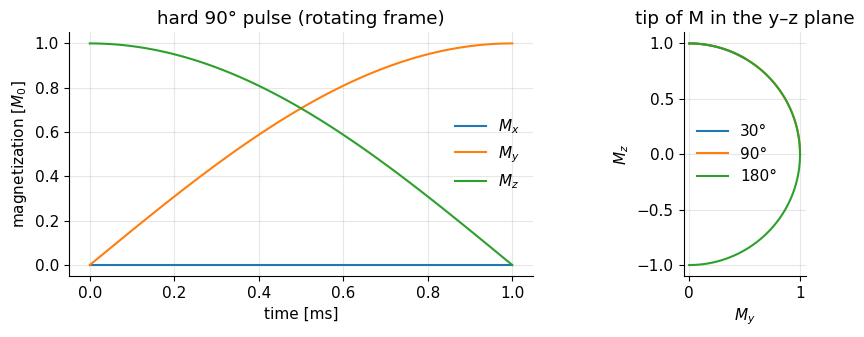

In [2]:
# Hard (rectangular) 90-degree pulse along +x, on resonance
theta = np.deg2rad(90)          # flip angle [rad]
T_rf = 1e-3                     # pulse duration [s] (1 ms)
dt = 10e-6                      # simulation step [s] (10 us)
b1_amp = mt.b1_for_flip(theta, T_rf)   # theta / (gamma * T_rf)  [T]
print(f"required B1 amplitude: {b1_amp*1e6:.2f} uT")

n = int(round(T_rf / dt))
b1 = np.full(n, b1_amp, dtype=complex)     # real -> field along +x in the rotating frame
t, M = mt.bloch_simulate(B1=b1, dt=dt)     # starts at M = [0, 0, 1]
print("final M =", np.round(M[-1, 0], 4))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
mt.plot_magnetization(t, M, ax=ax[0], title="hard 90° pulse (rotating frame)")
for th_deg in [30, 90, 180]:
    t2, M2 = mt.bloch_simulate(B1=np.full(n, mt.b1_for_flip(np.deg2rad(th_deg), T_rf), complex), dt=dt)
    ax[1].plot(M2[:, 0, 1], M2[:, 0, 2], label=f"{th_deg}°")
ax[1].set_xlabel(r"$M_y$"); ax[1].set_ylabel(r"$M_z$"); ax[1].set_aspect("equal")
ax[1].set_title("tip of M in the y–z plane"); ax[1].legend()
plt.tight_layout(); plt.show()

*Interpretation:* $M_z$ goes from 1 to 0 while $M_y$ goes from 0 to 1 along a circle: a field along $+x$ tips $\vec M$ toward $+y$ (left-handed rotation, consistent with $M_{xy}\propto e^{-i\omega t}$). Doubling the amplitude (or the duration) doubles the angle: 180° ends at $M_z=-1$.

### Rotating-frame Bloch equation in complex form

For the off-resonance analysis below we need the Bloch equation in the rotating frame, written with $M_{xy}=M_x+iM_y$ and $\vec B_{eff}=[\mathrm{Re}\,b_1,\mathrm{Im}\,b_1,\Delta\omega/\gamma]^T$:

$$\frac{dM_{xy}}{dt}=-i\,\Delta\omega\,M_{xy}+i\gamma\,b_1(t)\,M_z,\qquad \frac{dM_z}{dt}=\gamma\,\mathrm{Im}\!\left(M_{xy}^*\,b_1\right).$$

*In words:* the transverse magnetization precesses at the off-resonance frequency (first term) and is "fed" from $M_z$ by the RF field (second term); $M_z$ is in turn drained by the RF field.

where $\Delta\omega=2\pi\Delta f$ [rad/s], $b_1$ [T], $M_{xy}^*$ is the complex conjugate. We will only need the first equation.

<details><summary><b>📐 Derivation (optional)</b></summary>

From $d\vec M/dt=\gamma\vec M\times\vec B$ with $\vec B=[B_x,B_y,B_z]$:
$\dot M_x=\gamma(M_yB_z-M_zB_y)$, $\dot M_y=\gamma(M_zB_x-M_xB_z)$, $\dot M_z=\gamma(M_xB_y-M_yB_x)$.

Then $\dot M_{xy}=\dot M_x+i\dot M_y=\gamma B_z(M_y-iM_x)+i\gamma M_z(B_x+iB_y)$. Since $M_y-iM_x=-i(M_x+iM_y)=-iM_{xy}$ and $B_x+iB_y=b_1$, $B_z=\Delta\omega/\gamma$:
$\dot M_{xy}=-i\Delta\omega M_{xy}+i\gamma b_1M_z$. ✔

For $M_z$: $M_xB_y-M_yB_x=\mathrm{Im}(M_{xy}^*b_1)$ (expand $(M_x-iM_y)(B_x+iB_y)$), so $\dot M_z=\gamma\,\mathrm{Im}(M_{xy}^*b_1)$.

Check: with $b_1=B_1$ real and $M_{xy}=iM_y$: $\dot M_z=\gamma\,\mathrm{Im}(-iM_yB_1)=-\gamma M_yB_1$ ✔ (matches the component form).

</details>

### Time–bandwidth product

The **bandwidth** $BW_{rf}$ [Hz] of a pulse is the width of the band of frequencies it excites (we use the full width at half maximum, FWHM, of the profile). The **time–bandwidth product** (TBW) characterizes the relationship between pulse duration $T_{rf}$ and bandwidth $BW_{rf}$ and is a fixed value for a given pulse shape. It is defined as

$$ TBW = T_{rf} \cdot BW_{rf} .$$

*In words:* if you stretch a given pulse shape to twice the duration, it excites half the bandwidth – the product stays constant (this is the "scaling" property of the Fourier transform, [RM4](../refreshers/RM4_Fourier_Properties.ipynb)).

where $T_{rf}$ [s] is the duration, $BW_{rf}$ [Hz] the bandwidth, and $TBW$ is dimensionless.

For a sinc or sinc-like pulse, the TBW is equal to the number of zero crossings in the pulse shape, **counting the two zeros at the ends of the pulse**. A sinc pulse of duration $T_{rf}$ and time–bandwidth $TBW$ is

$$b_1(t)=A\,\mathrm{sinc}\!\left(\frac{TBW\,(t-T_{rf}/2)}{T_{rf}}\right)w(t),\qquad 0\le t\le T_{rf},$$

*In words:* a sinc centred in the pulse, whose lobes are $t_0=T_{rf}/TBW$ wide, optionally multiplied by a smooth window $w(t)$, scaled by $A$ to reach the desired flip angle.

where $A$ [T] is the amplitude, $\mathrm{sinc}(x)=\sin(\pi x)/(\pi x)$, $w(t)$ a window (=1 for no window). Its zeros are at $t-T_{rf}/2=\pm t_0,\pm2t_0,\dots$; a pulse with $TBW=4$ has one central lobe and one side lobe on each side ("3 lobes" = $TBW-1$ lobes). An untruncated sinc of lobe width $t_0$ has the Fourier transform $t_0\,\mathrm{rect}(f\,t_0)$, a perfect band of width $1/t_0=TBW/T_{rf}$ ([RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)). Truncating to finite duration rounds the edges.

Let us verify numerically: we compute the Fourier transform of sinc pulses of the same duration (4 ms) but different TBW and measure the FWHM bandwidth.

 TBW | lobes | zero crossings incl. ends | FWHM [Hz] | FWHM*T_rf   (no window / Hamming)
   2 |     1 |                         2 |       433 |  1.73 /  2.30


   4 |     3 |                         4 |       957 |  3.83 /  3.99
   6 |     5 |                         6 |      1464 |  5.86 /  5.99


   8 |     7 |                         8 |      1968 |  7.87 /  7.99
  12 |    11 |                        12 |      2971 | 11.88 / 11.99


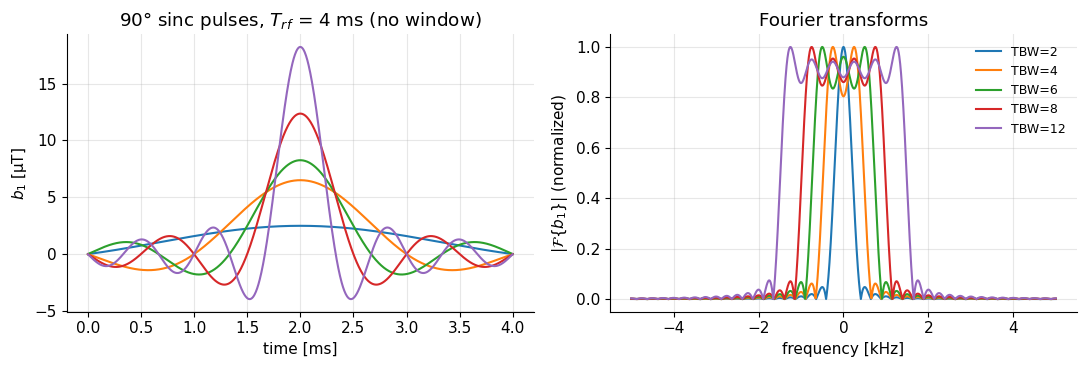

In [3]:
def sinc_pulse(TBW, T_rf, dt, theta=np.pi/2, window="hamming"):
    """Sinc pulse b1(t) [T] with time-bandwidth TBW, duration T_rf [s], step dt [s], flip theta [rad].
    window: 'none', 'hamming' or 'hann'. Returns (t, b1) with t at sample centres, 0..T_rf."""
    n = int(round(T_rf / dt))
    t = (np.arange(n) + 0.5) * dt                      # sample centres [s]
    x = (t - T_rf / 2) / T_rf                          # -0.5 .. 0.5
    w = {"none": np.ones(n),
         "hamming": 0.54 + 0.46 * np.cos(2 * np.pi * x),
         "hann": 0.5 + 0.5 * np.cos(2 * np.pi * x)}[window]
    shape = np.sinc(TBW * x) * w
    b1 = theta * shape / (mt.GAMMA * np.sum(shape) * dt)   # signed area -> flip angle theta
    return t, b1.astype(complex)

def spectrum(b1, t, dt, f):
    """Continuous FT  B(f) = integral b1(t) exp(-i 2 pi f t) dt, evaluated as a Riemann sum
    (time centred on the pulse middle).  b1 [T], t [s], f [Hz] -> [T s]."""
    tc = t - t.mean()
    return np.exp(-2j * np.pi * np.outer(f, tc)) @ b1 * dt

def fwhm(f, prof):
    """Full width at half maximum [Hz] of a non-negative profile, by linear interpolation."""
    p = prof / prof.max(); above = np.where(p >= 0.5)[0]; i0, i1 = above[0], above[-1]
    fl = np.interp(0.5, [p[i0 - 1], p[i0]], [f[i0 - 1], f[i0]])
    fr = np.interp(0.5, [p[i1 + 1], p[i1]], [f[i1 + 1], f[i1]])
    return fr - fl

T_rf, dt = 4e-3, 4e-6
f = np.linspace(-5000, 5000, 2001)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
print(" TBW | lobes | zero crossings incl. ends | FWHM [Hz] | FWHM*T_rf   (no window / Hamming)")
for TBW in [2, 4, 6, 8, 12]:
    t, b1 = sinc_pulse(TBW, T_rf, dt, window="none")
    _, b1h = sinc_pulse(TBW, T_rf, dt, window="hamming")
    S, Sh = np.abs(spectrum(b1, t, dt, f)), np.abs(spectrum(b1h, t, dt, f))
    s = np.real(b1); zc = np.sum(np.diff(np.sign(s)) != 0) + 2
    print(f"{TBW:4d} | {TBW-1:5d} | {zc:25d} | {fwhm(f, S):9.0f} | {fwhm(f, S)*T_rf:5.2f} / {fwhm(f, Sh)*T_rf:5.2f}")
    ax[0].plot(t * 1e3, b1.real * 1e6, label=f"TBW={TBW}")
    ax[1].plot(f / 1e3, S / S.max(), label=f"TBW={TBW}")
ax[0].set_xlabel("time [ms]"); ax[0].set_ylabel(r"$b_1$ [µT]"); ax[0].set_title("90° sinc pulses, $T_{rf}$ = 4 ms (no window)")
ax[1].set_xlabel("frequency [kHz]"); ax[1].set_ylabel(r"$|\mathcal{F}\{b_1\}|$ (normalized)"); ax[1].set_title("Fourier transforms")
ax[1].legend(fontsize=9); plt.tight_layout(); plt.show()

*Interpretation:* for TBW ≥ 4 the measured $FWHM\cdot T_{rf}$ is within ~3 % of the nominal TBW (and the zero-crossing count reproduces TBW); for TBW = 2 (a single lobe, essentially a cosine bump) the "rect" picture no longer holds and the FWHM deviates by 15–20 %: for a fixed duration, more lobes = wider band, with sharper edges *relative to the band width*. Note also that the peak $b_1$ grows with TBW – the price for more lobes (more on that in the SAR section). The truncated, unwindowed sinc shows ripples ("Gibbs ringing") at the band edges.

### Windowing (apodization)

Cutting a sinc off abruptly multiplies it by a rect; in the frequency domain this **convolves** the ideal rect profile with a sinc, producing ripples (convolution theorem, [RM4](../refreshers/RM4_Fourier_Properties.ipynb)). Multiplying the pulse by a smooth **window** $w(t)$ that goes to (nearly) zero at the ends reduces the ripples, at the cost of a slightly wider transition band. Common choices: Hamming $w=0.54+0.46\cos(2\pi x)$ and Hann $w=0.5+0.5\cos(2\pi x)$ with $x=(t-T_{rf}/2)/T_{rf}\in[-\tfrac12,\tfrac12]$.

none    : passband ripple (peak-peak) 13.11 %, max stopband level  -29.4 dB, transition width (90%->10%)   245 Hz, FWHM*T = 5.86
hamming : passband ripple (peak-peak)  1.01 %, max stopband level  -41.9 dB, transition width (90%->10%)   460 Hz, FWHM*T = 5.99
hann    : passband ripple (peak-peak)  1.65 %, max stopband level  -40.4 dB, transition width (90%->10%)   485 Hz, FWHM*T = 5.99


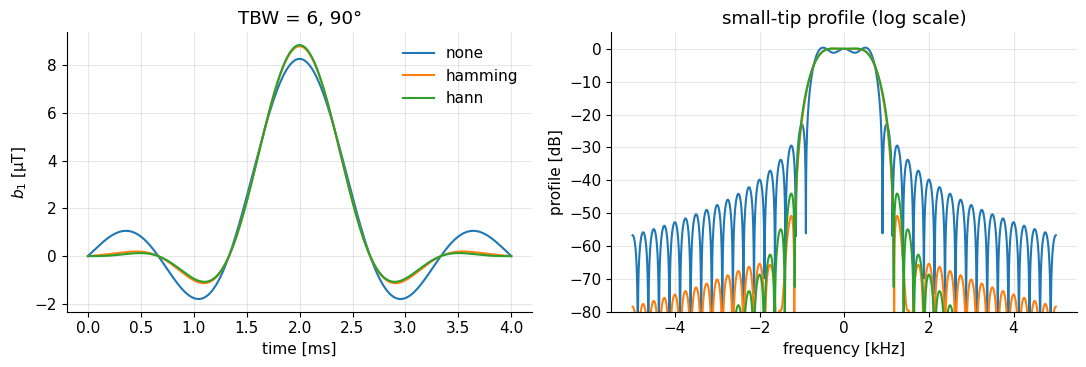

In [4]:
TBW = 6
BW = TBW / T_rf
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for win in ["none", "hamming", "hann"]:
    t, b1 = sinc_pulse(TBW, T_rf, dt, window=win)
    S = np.abs(spectrum(b1, t, dt, f)); S /= S[np.argmin(np.abs(f))]     # normalize to centre
    passb = np.abs(f) < 0.5 * BW / 2          # inner half of the band
    stop = np.abs(f) > 1.5 * BW / 2           # outside 1.5x the half-width
    pos = f >= 0
    fp, Sp = f[pos], S[pos]
    i90 = np.where(Sp >= 0.9)[0].max()                       # last point still >= 90 %
    i10 = i90 + np.argmax(Sp[i90:] <= 0.1)                   # first point after it <= 10 %
    f90, f10 = fp[i90], fp[i10]
    print(f"{win:8s}: passband ripple (peak-peak) {100*(S[passb].max()-S[passb].min()):5.2f} %, "
          f"max stopband level {20*np.log10(S[stop].max()):6.1f} dB, "
          f"transition width (90%->10%) {f10-f90:5.0f} Hz, FWHM*T = {fwhm(f, S)*T_rf:.2f}")
    ax[0].plot(t * 1e3, b1.real * 1e6, label=win)
    ax[1].plot(f / 1e3, 20 * np.log10(S + 1e-6), label=win)
ax[0].set_xlabel("time [ms]"); ax[0].set_ylabel(r"$b_1$ [µT]"); ax[0].set_title(f"TBW = {TBW}, 90°"); ax[0].legend()
ax[1].set_ylim(-80, 5); ax[1].set_xlabel("frequency [kHz]"); ax[1].set_ylabel("profile [dB]"); ax[1].set_title("small-tip profile (log scale)")
plt.tight_layout(); plt.show()

*Interpretation:* without a window the passband wobbles by several % and the out-of-band side lobes are only ~25–30 dB below the passband (a few % of the flip angle lands outside the band); the Hamming and Hann windows push the side lobes down to about −40 dB and below (further out even −60 dB) and make the passband flat to ~1 %. The price is a wider transition band (the edges are less steep), while the FWHM bandwidth barely changes. This is why "sinc pulse" in practice almost always means **windowed sinc**. Optimal trade-offs between ripple and transition width are the subject of [RF Pulse Design](E3_RF_Pulse_Design.ipynb).

### Specific absorption rate (SAR)

The **specific absorption rate** (SAR) measures the RF power absorbed by the body per kilogram of tissue [W/kg]. Since this absorption heats tissue, there are safety limits on SAR. Physically, the changing RF magnetic field induces electric fields $\vec E$ in the conductive tissue (Faraday's law, [RP2](../refreshers/RP2_Induction_and_RF.ipynb)); the resulting currents dissipate power $\sigma_{el}|\vec E|^2$ per volume. Because $|\vec E|$ is proportional to the rate of change of $B_1$, i.e. to $\omega_0 B_1$, the energy deposited by one pulse is

$$ E_{pulse}\ \propto\ \omega_0^2\int_0^{T_{rf}} |b_1(\tau)|^2\, d\tau ,\qquad SAR\ \propto\ \frac{\omega_0^2}{TR}\sum_{\text{pulses in }TR}\int|b_1|^2\,d\tau .$$

*In words:* the heating is proportional to the integrated *squared* RF amplitude ("RF power" × time), to the square of the Larmor frequency, and to how often pulses are played (number per $TR$, divided by $TR$).

where $E_{pulse}$ [J] is the energy of one pulse (the proportionality constant depends on the coil and the patient's size/conductivity), $\omega_0=\gamma B_0$ [rad/s], $b_1$ [T], $T_{rf}$ [s] the duration, $TR$ [s] the repetition time. Locally, $SAR=\sigma_{el}|\vec E|^2/\rho$ with conductivity $\sigma_{el}$ [S/m] and density $\rho$ [kg/m³].

**Scaling rules** for a fixed pulse *shape* (derivation: $b_1\propto\theta/T_{rf}$, so $\int|b_1|^2dt\propto(\theta/T_{rf})^2\cdot T_{rf}$):

$$SAR\ \propto\ B_0^2\ \cdot\ \frac{\theta^2}{T_{rf}}\ \cdot\ \frac{N_{pulses}}{TR}.$$

*In words:* doubling the flip angle quadruples SAR; halving the pulse duration doubles SAR; going from 1.5 T to 3 T quadruples SAR for the same sequence.

where $N_{pulses}$ is the number of RF pulses per $TR$.

In [5]:
# RF energy integral(|b1|^2 dt) of different 90-degree pulses, all T_rf = 2 ms
T_rf, dt = 2e-3, 4e-6
def energy(b1, dt):
    return np.sum(np.abs(b1)**2) * dt              # [T^2 s]

n = int(round(T_rf / dt))
hard = np.full(n, mt.b1_for_flip(np.pi/2, T_rf), complex)
E_hard = energy(hard, dt)
print(f"{'pulse (90°, 2 ms)':28s} {'peak B1 [uT]':>12s} {'energy rel. to hard':>20s}")
print(f"{'hard':28s} {np.abs(hard).max()*1e6:12.2f} {1.0:20.2f}")
for TBW in [2, 4, 8, 12]:
    _, b1 = sinc_pulse(TBW, T_rf, dt, theta=np.pi/2, window="hamming")
    print(f"{'Hamming sinc, TBW=' + str(TBW):28s} {np.abs(b1).max()*1e6:12.2f} {energy(b1, dt)/E_hard:20.2f}")

# scaling checks with the TBW=4 sinc
_, b_ref = sinc_pulse(4, 2e-3, dt, np.pi/2)
for lab, (th, T) in {"180° instead of 90°": (np.pi, 2e-3), "1 ms instead of 2 ms": (np.pi/2, 1e-3)}.items():
    _, b = sinc_pulse(4, T, dt, th)
    print(f"TBW=4 sinc, {lab:22s}: energy x {energy(b, dt)/energy(b_ref, dt):.2f}, peak B1 x {np.abs(b).max()/np.abs(b_ref).max():.2f}")
print("Same sequence at 3 T vs 1.5 T: SAR x", (3.0/1.5)**2)

pulse (90°, 2 ms)            peak B1 [uT]  energy rel. to hard
hard                                 2.94                 1.00
Hamming sinc, TBW=2                  6.95                 1.72
Hamming sinc, TBW=4                 11.70                 3.20
Hamming sinc, TBW=8                 23.54                 7.26
Hamming sinc, TBW=12                35.30                11.27
TBW=4 sinc, 180° instead of 90°   : energy x 4.00, peak B1 x 2.00
TBW=4 sinc, 1 ms instead of 2 ms  : energy x 2.00, peak B1 x 2.00
Same sequence at 3 T vs 1.5 T: SAR x 4.0


*Interpretation:* a TBW-4 Hamming sinc needs ~4× the peak $B_1$ of a hard pulse of the same duration and deposits ~3× more energy; TBW 12 needs ~12× the peak and ~11× the energy (roughly: energy ∝ TBW for a fixed duration). The scaling checks reproduce $\theta^2$ (×4) and $1/T_{rf}$ (×2). This is why sharp, short, large-flip-angle pulses (180° refocusing trains in fast spin echo) are often **SAR-limited**, especially at 3 T and above.

> **🔧 Engineering reality:** Regulatory limits (IEC 60601-2-33, "normal operating mode"): whole-body SAR ≤ 2 W/kg, head SAR ≤ 3.2 W/kg, averaged over 6 minutes (and stricter short-term limits). The scanner predicts SAR from a patient model (weight) and the pulse sequence before the scan and will lengthen $TR$, reduce flip angles, stretch pulses or reduce the number of slices if needed. Peak $B_1$ is limited separately by the RF power amplifier: power ∝ $B_1^2$, and body-coil systems at 1.5–3 T typically deliver on the order of 15–25 µT peak $B_1^+$ with amplifiers of tens of kW peak power (exact values depend on vendor, coil and patient loading). A 180° Hamming-sinc pulse of 1 ms with TBW 4 would need ≈ 47 µT (table above: 11.7 µT × 2 for 180° × 2 for half the duration) – often impossible in the body coil, so the pulse must be made longer. More: [B5 RF System](B5_RF_System_and_Receive_Chain.ipynb), [B6 MRI Safety](B6_MRI_Safety.ipynb).

## Hard pulse versus shaped pulse

The first RF pulse typically introduced in MRI education is the so-called **"hard" pulse** – a constant amplitude applied for some period of time. As shown below, this pulse performs poorly for slice selection, so **shaped**, sinc-like pulses are used. Shaped pulses create frequency profiles that excite a range of frequencies approximately uniformly (with the same flip angle), while not exciting spins outside this frequency range.

### On-resonance excitation

We can visualize the rotation of the net magnetization as before, as a rotation about the RF field vector (in the rotating frame), for hard and shaped pulses:

**Hard pulse:**

![Hard pulse on resonance: M rotates steadily about the RF field](../images/hard_pulse_center_frequency.gif)

**Shaped pulse:**

![Shaped (sinc) pulse on resonance: M is tipped back and forth](../images/sinc_pulse_center_frequency.gif)

Looking at the on-resonance (center-frequency) response of a sinc-like shaped pulse, the flip angle is achieved slightly differently: the negative side lobes tip the net magnetization back a little, the big central lobe tips it far forward, and the net result is the same flip angle (the *signed* area of $b_1$).

### Off-resonance excitation

The flip angle produced by a hard pulse varies substantially as a function of off-resonance frequency (e.g. in the presence of a magnetic field gradient), so it is not a good pulse for slice selection. The sinc-like pulse becomes advantageous when considering a range of resonance frequencies: its pattern of back-and-forth tipping leads to net magnetizations being either flipped or not.

This is illustrated by the following animations, showing net magnetizations across a range of positions when the pulse is applied with a gradient:

**Hard pulse:**

![Hard pulse with a gradient: wide spread of flip angles across positions](../images/hard_pulse_frequencies.gif)

**Shaped pulse:**

![Sinc pulse with a gradient: magnetizations are either ~90° or ~0°](../images/sinc_pulse_frequencies.gif)

These simulations are for an identical range of positions. With the *hard pulse* the resulting magnetizations are spread over a wide range of flip angles at different positions, whereas with the sinc-like pulse the majority of net magnetizations are either at approximately 90° or 0°, with very few intermediate flip angles. (Also note the **refocusing gradient** at the end, which is necessary to correct for the additional phase accumulated during the gradient and RF – see [Slice Selection](E2_Slice_Selection.ipynb).)

The same with many more spins:

![Hard pulse, many positions](../images/hard_pulse_frequencies-many.gif)

![Sinc pulse, many positions](../images/sinc_pulse_frequencies-many.gif)

This behavior can be analyzed by simulating the RF pulse profile with the Bloch equation, which is more precise than the Fourier-transform approximation introduced later.

## RF pulse profile

To precisely characterize the behavior of an RF pulse, we compute its **pulse profile**: the result of the pulse as a function of off-resonance frequency $\Delta f$. (In the next chapter gradients are added and the profile becomes a function of position.) A profile can show the flip angle $\theta(f)$, the resulting transverse magnetization $|M_{xy}|$, or the resulting longitudinal magnetization $M_z$.

The following simulation (port of the original Octave/Python cell) computes the magnetization profiles after a hard pulse (1.5 ms) and a Hamming-windowed sinc pulse (8 ms, lobe width 1 ms → TBW = 8, $BW_{rf}$ = 1 kHz), both 90°. Instead of looping over spins one at a time, `mt.bloch_simulate` simulates all 100 frequencies at once (vectorized).

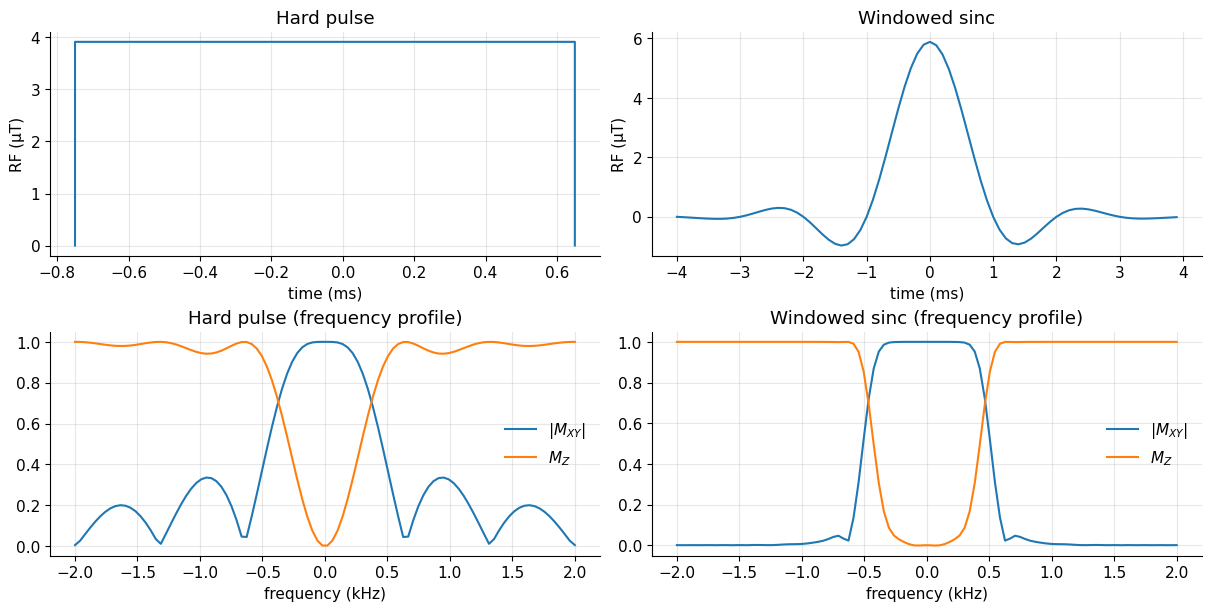

In [6]:
# Units: SI (s, T, Hz).  The original used ms, mT, kHz.
flip = np.deg2rad(90.0)
dt = 0.1e-3                      # 0.1 ms
df = np.linspace(-2000, 2000, 100)   # off-resonance frequencies [Hz]

# ---------- Hard pulse ----------
tmax_hard = 1.5e-3
N_hard = int(round(tmax_hard / dt))
t_hard = (np.arange(N_hard) - N_hard / 2) * dt
RF_hard = np.ones(N_hard)
RF_hard = flip * RF_hard / RF_hard.sum() / (mt.GAMMA * dt)        # [T]
_, M_hard = mt.bloch_simulate(B1=RF_hard.astype(complex), dt=dt, df=df, return_all=False)

# ---------- Windowed sinc pulse ----------
tmax_sinc = 8e-3
N_sinc = int(round(tmax_sinc / dt))
t_sinc = (np.arange(N_sinc) - N_sinc // 2) * dt
RF_sinc = np.hamming(N_sinc) * np.sinc(t_sinc / 1e-3)              # lobe width 1 ms
RF_sinc = flip * RF_sinc / RF_sinc.sum() / (mt.GAMMA * dt)          # [T]
_, M_sinc = mt.bloch_simulate(B1=RF_sinc.astype(complex), dt=dt, df=df, return_all=False)

fig, axs = plt.subplots(2, 2, figsize=(12, 6), constrained_layout=True)
eps = 1e-9
axs[0, 0].plot(np.hstack([t_hard[0] - eps, t_hard, t_hard[-1] + eps]) * 1e3, np.hstack([0, RF_hard, 0]) * 1e6)
axs[0, 0].set(xlabel="time (ms)", ylabel="RF (µT)", title="Hard pulse")
axs[1, 0].plot(df / 1e3, np.abs(M_hard[:, 0] + 1j * M_hard[:, 1]), label=r"$|M_{XY}|$")
axs[1, 0].plot(df / 1e3, M_hard[:, 2], label=r"$M_{Z}$")
axs[1, 0].set(title="Hard pulse (frequency profile)", xlabel="frequency (kHz)"); axs[1, 0].legend()
axs[0, 1].plot(t_sinc * 1e3, RF_sinc * 1e6)
axs[0, 1].set(xlabel="time (ms)", ylabel="RF (µT)", title="Windowed sinc")
axs[1, 1].plot(df / 1e3, np.abs(M_sinc[:, 0] + 1j * M_sinc[:, 1]), label=r"$|M_{XY}|$")
axs[1, 1].plot(df / 1e3, M_sinc[:, 2], label=r"$M_{Z}$")
axs[1, 1].set(title="Windowed sinc (frequency profile)", xlabel="frequency (kHz)"); axs[1, 1].legend()
plt.show()

*Interpretation:* the hard pulse is short (1.5 ms), so it excites a broad band, but its profile has a rounded top and large side lobes (it is a sinc in frequency – the FT of a rect). The windowed sinc excites a nearly flat band of ≈ 1 kHz with sharp edges and almost nothing outside: a **frequency-selective** pulse. Note the peak amplitudes: ~3.9 µT (hard) vs ~5.9 µT (sinc), even though the sinc pulse is 5× longer.

## Frequency content in RF pulses

For RF pulses, we generally want to control the frequencies that are excited. Most commonly, we want to excite a range of frequencies that will then correspond to a range of positions, to excite a slice.

### Sum of frequencies

One way to think of RF pulse design is that we add a range of frequencies together in the RF pulse, which will then excite a range of off-resonance frequencies. This "sum of frequencies" view of RF pulses is shown in the following animations.

In the lab frame, this happens around the Larmor frequency:

![Adding more and more frequencies around the Larmor frequency builds up a sinc-like pulse (lab frame)](../images/RF_pulse_frequencies-lab_frame.gif)

In the rotating frame, the frequencies build up around frequency = 0:

![The same in the rotating frame, around 0 Hz](../images/RF_pulse_frequencies-rotating_frame.gif)

Below is a static Python version of the rotating-frame animation (port of `animate_RF_pulses.m`): we add complex exponentials $e^{i2\pi f_k t}$ with $f_k=0,\pm1,\pm2,\dots$ (in arbitrary units, e.g. kHz if $t$ is in ms) and look at the sum and its DFT.

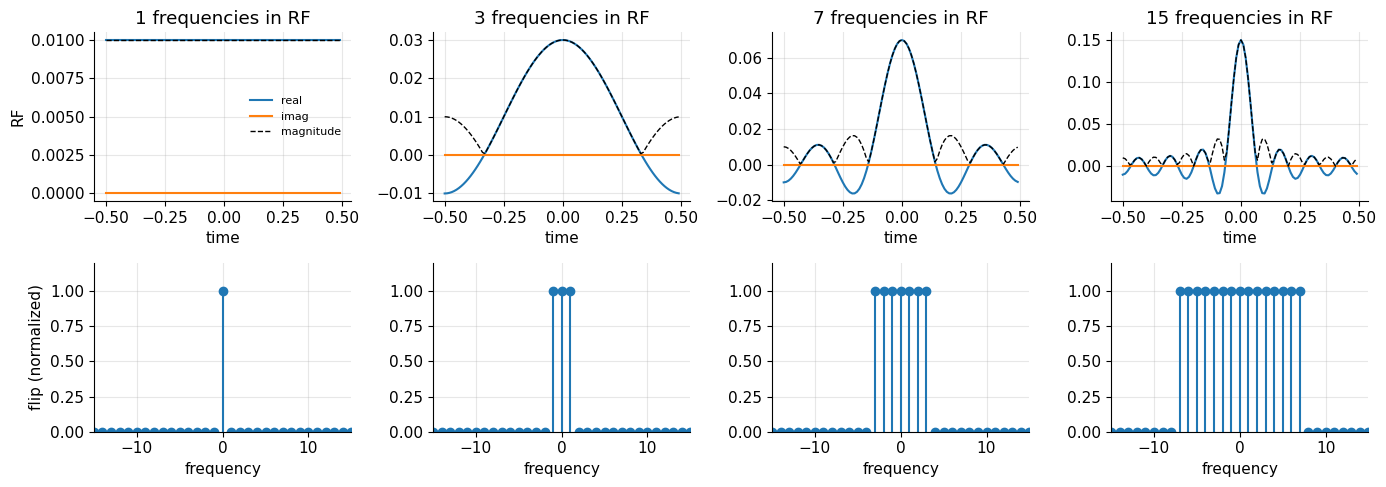

In [7]:
dt_a, tmax = 0.01, 1.0                    # arbitrary units (think: ms)
N = int(round(tmax / dt_a))
t_a = (np.arange(N) - N / 2) * dt_a
freqs = np.array([0, 1, -1, 2, -2, 3, -3, 4, -4, 5, -5, 6, -6, 7, -7])   # order in which they are added
f_axis = (np.arange(N) - N / 2) / (N * dt_a)

fig, axs = plt.subplots(2, 4, figsize=(14, 5), sharex="row")
for col, nf in enumerate([1, 3, 7, 15]):
    rf_n = np.sum(np.exp(1j * 2 * np.pi * np.outer(freqs[:nf], t_a)), axis=0) * dt_a
    FT_n = np.fft.fftshift(np.fft.fft(rf_n))                # DFT approximates the continuous FT (up to scaling)
    axs[0, col].plot(t_a, rf_n.real, label="real"); axs[0, col].plot(t_a, rf_n.imag, label="imag")
    axs[0, col].plot(t_a, np.abs(rf_n), "k--", lw=1, label="magnitude")
    axs[0, col].set_title(f"{nf} frequencies in RF"); axs[0, col].set_xlabel("time")
    axs[1, col].stem(f_axis, np.abs(FT_n), basefmt=" ")
    axs[1, col].set_xlim(-15, 15); axs[1, col].set_ylim(0, 1.2); axs[1, col].set_xlabel("frequency")
axs[0, 0].set_ylabel("RF"); axs[0, 0].legend(fontsize=8); axs[1, 0].set_ylabel("flip (normalized)")
plt.tight_layout(); plt.show()

*Interpretation:* with one frequency (0) the pulse is constant (a hard pulse). Adding symmetric pairs $\pm f_k$ keeps the pulse real and builds up a sinc-like shape that gets narrower in time as the band of frequencies gets wider – the time–bandwidth trade-off in action.

### Fourier transform (small-tip) approximation

Based on the above illustration, the profile of an RF pulse looks like a Fourier transform – an operation that determines the frequency content of a signal. In practice the RF pulse profile is only *approximately* proportional to the Fourier transform of the RF pulse shape, but this approximation is extremely useful:

$$\theta(f) \approx \gamma\, \bigl|\mathcal{F}\{b_1(t)\}(f)\bigr| ,$$

*In words:* the flip angle that spins at frequency offset $f$ receive is (approximately) $\gamma$ times the magnitude of the Fourier transform of the RF envelope at that frequency.

where $b_1(t)$ [T] is the RF pulse shape, $\mathcal F\{b_1\}(f)=\int b_1(t)e^{-i2\pi ft}dt$ [T·s], and $\theta(f)$ [rad] is the flip angle at frequency $f$. For real, symmetric pulses the sign of $f$ does not matter. (The original writes this without the magnitude; for a pulse centred at $t=0$ and real and even, $\mathcal F\{b_1\}$ is real, so the two agree up to a sign.)

> **🔁 Refresher:** You know the DFT; the continuous FT is its limit for infinitely fine and long sampling, with $f$ in Hz. Translation table and the role of `fftshift`: [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb). Rect ↔ sinc and windowing: [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb).

#### Derivation (the small-tip approximation)

Start from the complex rotating-frame Bloch equation derived above, for a spin with off-resonance $\Delta f$:

$$\frac{dM_{xy}}{dt}=-i2\pi\Delta f\,M_{xy}+i\gamma\,b_1(t)\,M_z .$$

*In words:* transverse magnetization precesses (clockwise) at $\Delta f$ and is created from $M_z$ by the RF.

**Small-tip assumption:** for small flip angles $M_z$ barely changes, so we replace it by its starting value, $M_z\approx M_0$. The equation becomes a *linear* first-order ODE with a source term, which is solved with an integrating factor ([RM1](../refreshers/RM1_ODEs_for_MRI.ipynb)). With $M_{xy}(0)=0$, at the end of the pulse ($t=T_{rf}$):

$$M_{xy}(\Delta f, T_{rf})\approx i\gamma M_0\int_0^{T_{rf}} b_1(t)\,e^{-i2\pi\Delta f\,(T_{rf}-t)}\,dt
= i\gamma M_0\, e^{-i\pi\Delta f T_{rf}}\int_{-T_{rf}/2}^{T_{rf}/2} b_1\!\left(s+\tfrac{T_{rf}}{2}\right)e^{+i2\pi\Delta f s}\,ds .$$

*In words:* every small piece of RF at time $t$ creates a little bit of transverse magnetization (along +y for a real $b_1$, that is the factor $i$), which then precesses at $\Delta f$ for the remaining time $T_{rf}-t$. Adding up all pieces gives a Fourier-type integral of the pulse shape.

where $M_0$ is the equilibrium magnetization, $\gamma$ [rad s⁻¹T⁻¹], $b_1$ [T], $\Delta f$ [Hz], $T_{rf}$ [s], and $s=t-T_{rf}/2$ is time measured from the pulse centre. Comparing with $\mathcal F\{g\}(f)=\int g(s)e^{-i2\pi fs}ds$:

$$M_{xy}(\Delta f)\approx i\gamma M_0\;e^{-i\pi\Delta f T_{rf}}\;\mathcal F\{b_1^{c}\}(-\Delta f),\qquad b_1^{c}(s)=b_1(s+T_{rf}/2).$$

*In words:* up to a constant factor $i\gamma M_0$ and a **linear phase** $e^{-i\pi\Delta f T_{rf}}$, the excitation profile is the Fourier transform of the centred pulse shape, evaluated at $-\Delta f$. The magnitude is the original book's $\theta(f)\approx\gamma|\mathcal F\{b_1\}|$ (for small angles $|M_{xy}|\approx M_0\theta$).

Three things to notice:

1. **Sign convention.** With the left-handed precession $e^{-i\omega t}$ used throughout this course, the profile at $+\Delta f$ is the FT at $-\Delta f$ (equivalently an *inverse* FT). For real symmetric pulses $|\mathcal F|$ is even, so it does not matter; for frequency-shifted pulses it decides the direction of the shift (next sections, and [E2](E2_Slice_Selection.ipynb)).
2. **Linear phase.** The factor $e^{-i\pi\Delta fT_{rf}}$ means that, for a symmetric pulse, spins behave as if they were tipped instantaneously at the pulse centre and then precessed freely for $T_{rf}/2$. In slice selection this phase is undone by the refocusing (rewinder) gradient.
3. **Linearity.** Doubling $b_1$ doubles $M_{xy}$ – true only while $M_z\approx M_0$. At 90°, $M_z$ drops to 0, so the approximation must fail.

<details><summary><b>📐 Integrating-factor step (optional)</b></summary>

Write the ODE as $\dot M_{xy}+i2\pi\Delta f\,M_{xy}=i\gamma M_0b_1(t)$. Multiply by $e^{i2\pi\Delta f t}$: the left side becomes $\frac{d}{dt}\left(M_{xy}e^{i2\pi\Delta f t}\right)$. Integrate from 0 to $T_{rf}$ with $M_{xy}(0)=0$:
$M_{xy}(T_{rf})e^{i2\pi\Delta fT_{rf}}=i\gamma M_0\int_0^{T_{rf}}b_1(t)e^{i2\pi\Delta ft}dt$, i.e.
$M_{xy}(T_{rf})=i\gamma M_0\int_0^{T_{rf}}b_1(t)e^{-i2\pi\Delta f(T_{rf}-t)}dt$. Substituting $t=s+T_{rf}/2$ gives the centred form.

</details>

In practice this approximation is valid for **small flip angles** – it is surprisingly good up to about 30–60°. Let us test it against Bloch simulations for 30°, 90° and 180° with the same pulse shape (Hamming-windowed sinc, TBW 8, $T_{rf}$ = 4 ms → $BW_{rf}$ = 2 kHz).

  30°: max |Mxy(Bloch) - Mxy(small tip)| = 0.028 M0;  on resonance: Bloch |Mxy| = 0.500, small tip = 0.524
  90°: max |Mxy(Bloch) - Mxy(small tip)| = 0.639 M0;  on resonance: Bloch |Mxy| = 1.000, small tip = 1.571
 180°: max |Mxy(Bloch) - Mxy(small tip)| = 3.169 M0;  on resonance: Bloch |Mxy| = 0.000, small tip = 3.142


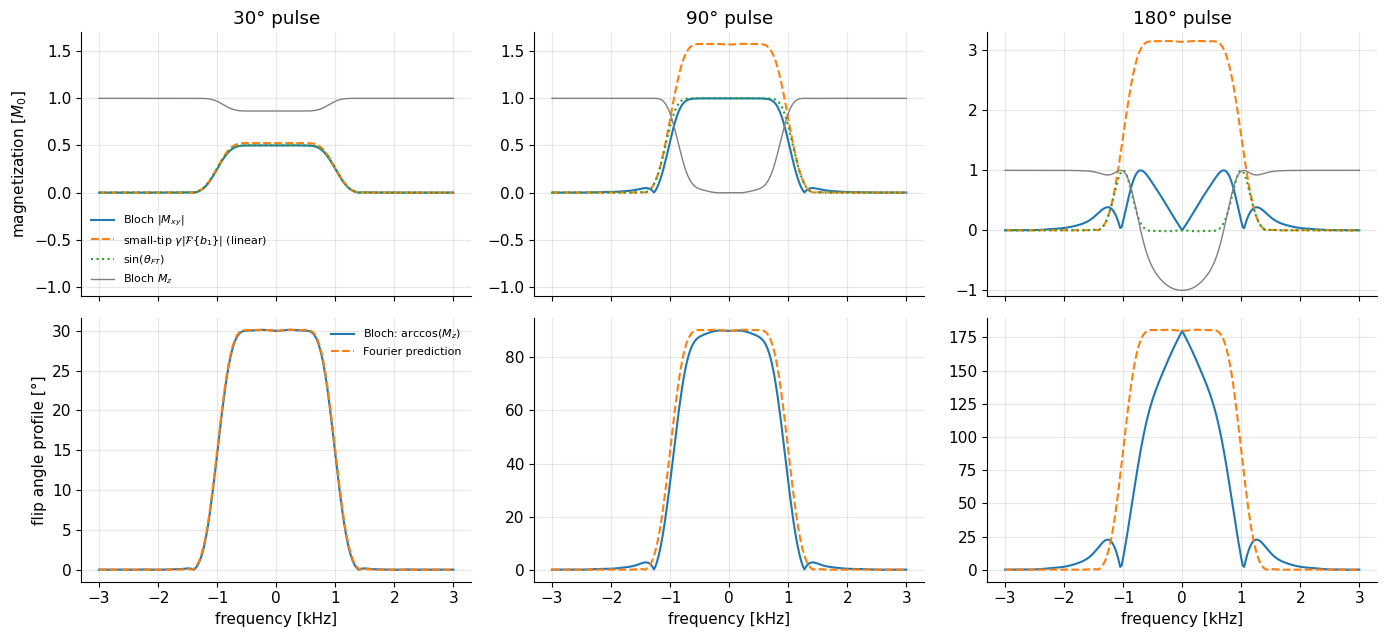

In [8]:
T_rf, dt = 4e-3, 10e-6
df = np.linspace(-3000, 3000, 241)                     # off-resonance [Hz]
fig, axs = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True)
for col, th_deg in enumerate([30, 90, 180]):
    t, b1 = sinc_pulse(8, T_rf, dt, theta=np.deg2rad(th_deg))
    # --- small-tip (Fourier) prediction, exact formula from the derivation (t runs 0..T_rf) ---
    Mxy_st = 1j * mt.GAMMA * np.exp(-2j * np.pi * np.outer(df, T_rf - t)) @ b1 * dt
    theta_st = np.abs(Mxy_st)                          # predicted flip angle [rad] (since |Mxy| ~ theta)
    # --- Bloch simulation (all frequencies at once) ---
    _, M = mt.bloch_simulate(B1=b1, dt=dt, df=df, return_all=False)
    Mxy_b = M[:, 0] + 1j * M[:, 1]
    theta_b = np.arccos(np.clip(M[:, 2], -1, 1))      # actual flip angle [rad]
    ax = axs[0, col]
    ax.plot(df / 1e3, np.abs(Mxy_b), label=r"Bloch $|M_{xy}|$")
    ax.plot(df / 1e3, theta_st, "--", label=r"small-tip $\gamma|\mathcal{F}\{b_1\}|$ (linear)")
    ax.plot(df / 1e3, np.sin(theta_st), ":", label=r"$\sin(\theta_{FT})$")
    ax.plot(df / 1e3, M[:, 2], color="gray", lw=1, label=r"Bloch $M_z$")
    ax.set_title(f"{th_deg}° pulse"); ax.set_ylim(-1.1, 3.3 if th_deg == 180 else 1.7)
    axs[1, col].plot(df / 1e3, np.rad2deg(theta_b), label="Bloch: arccos($M_z$)")
    axs[1, col].plot(df / 1e3, np.rad2deg(theta_st), "--", label="Fourier prediction")
    axs[1, col].set_xlabel("frequency [kHz]")
    err = np.max(np.abs(Mxy_b - Mxy_st))
    print(f"{th_deg:4d}°: max |Mxy(Bloch) - Mxy(small tip)| = {err:.3f} M0;  "
          f"on resonance: Bloch |Mxy| = {np.abs(Mxy_b[120]):.3f}, small tip = {theta_st[120]:.3f}")
axs[0, 0].set_ylabel("magnetization [$M_0$]"); axs[1, 0].set_ylabel("flip angle profile [°]")
axs[0, 0].legend(fontsize=8); axs[1, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

*Interpretation:*
* **30°:** Bloch and Fourier prediction are almost indistinguishable (error a few % of $M_0$, essentially $\theta-\sin\theta$).
* **90°:** the linear prediction overshoots ($\pi/2\approx1.57$ instead of 1), but the *shape* of the flip-angle profile (bottom) is still close; using $\sin(\theta_{FT})$ fixes most of the magnitude, though the transition bands and ripples begin to differ.
* **180°:** the Fourier prediction is qualitatively wrong for $M_{xy}$: on resonance a 180° pulse produces **no** transverse magnetization (it inverts), while its edges produce maximal $M_{xy}$. The flip-angle profile (bottom right) is no longer flat: only the very centre reaches 180°, the profile is rounded and side lobes of ~20° appear just outside the band. Large-flip-angle pulses must therefore be designed with methods that respect the non-linear Bloch equation, such as the **Shinnar–Le Roux (SLR)** algorithm ([RF Pulse Design](E3_RF_Pulse_Design.ipynb)).

![RF pulse profiles at small and large flip angles, computed with the Bloch equation and the Fourier transform approximation](../images/RF_Pulses-small_large_tip_example.png)

*Figure (original book): the same comparison – at small flip angles the FT approximation matches the Bloch simulation, at large flip angles it does not.*

> **🧭 Intuition:** The FT picture assumes every little piece of the pulse acts on "fresh" longitudinal magnetization. Once $M_z$ is substantially depleted, later pieces of the pulse act on an already rotated vector, and rotations about different axes do not simply add – the system is non-linear.

## Frequency-selective pulses for fat suppression

Fat is often a nuisance signal in MRI (bright on many sequences, and shifted in space by chemical shift – see [A3 In Vivo Spin Physics](A3_In_Vivo_Spin_Physics.ipynb) and [I2 Artifacts](I2_Artifacts.ipynb)). We can use frequency-selective RF pulses for fat suppression by applying a **saturation pulse** that tips fat by 90° but water by 0°. This works because of the chemical shift between fat and water ($\Delta f_{cs}\approx-3.5$ ppm, i.e. −224 Hz at 1.5 T and −447 Hz at 3 T). After the pulse, $M_{z,fat}=0$ but $M_{z,water}$ is unaffected. The pulse is followed by a **spoiler gradient** that dephases the transverse magnetization of fat, resulting in no signal from fat, $m_{fat}=0$, when the imaging excitation follows immediately.

To put the pulse's band at the fat frequency we use the **shift theorem** ([RM4](../refreshers/RM4_Fourier_Properties.ipynb)): multiplying the envelope by $e^{-i2\pi f_c t}$ moves its profile to $\Delta f=f_c$.

$$b_1^{shifted}(t)=b_1(t)\,e^{-i2\pi f_c t}\quad\Longrightarrow\quad\text{profile centred at }\Delta f=f_c .$$

*In words:* to excite spins that precess at $f_c$ relative to the RF carrier, the RF envelope must rotate along with them (clockwise at $f_c$) – equivalently, the scanner simply sets the transmitter frequency to $f_0+f_c$.

where $f_c$ [Hz] is the desired centre frequency of the excited band (here $f_c=\Delta f_{cs}<0$). The minus sign follows from our convention: in the small-tip integral $\int b_1(t)e^{+i2\pi\Delta ft}dt$ the factor $e^{-i2\pi f_ct}$ cancels exactly when $\Delta f=f_c$.

3.0 T: Mz(water) = 1.000,  Mz(fat) = 0.000,  peak B1 = 2.34 uT


1.5 T: Mz(water) = 1.000,  Mz(fat) = 0.000,  peak B1 = 1.17 uT


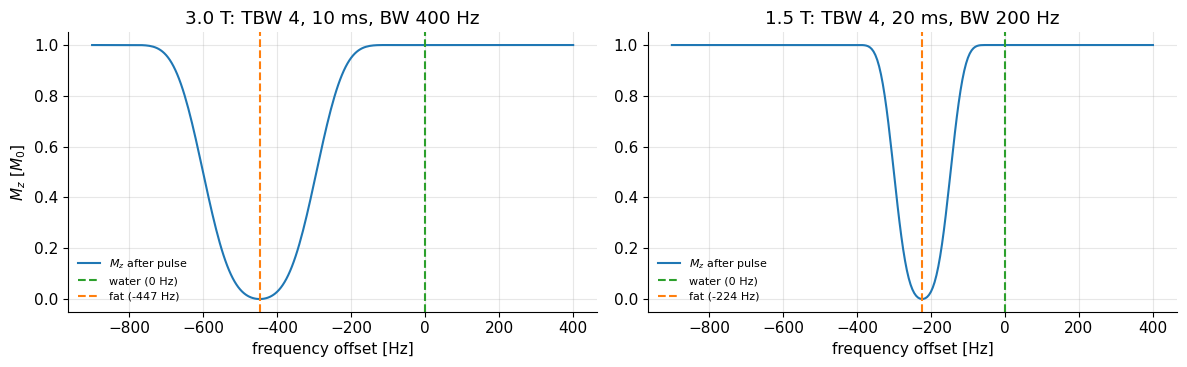

In [9]:
# Fat saturation pulse for 3 T: windowed sinc, TBW 4, T_rf 10 ms -> BW 400 Hz, centred on fat
dt = 20e-6
df = np.linspace(-900, 400, 261)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for i, (B0, T_rf) in enumerate([(3.0, 10e-3), (1.5, 20e-3)]):
    f_fat = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)            # [Hz], negative
    t, b1 = sinc_pulse(4, T_rf, dt, theta=np.pi/2)
    b1_fs = b1 * np.exp(-2j * np.pi * f_fat * t)          # shift the band to the fat frequency
    _, M = mt.bloch_simulate(B1=b1_fs, dt=dt, df=df, return_all=False)
    _, Mw = mt.bloch_simulate(B1=b1_fs, dt=dt, df=[0.0, f_fat], return_all=False)
    ax[i].plot(df, M[:, 2], label=r"$M_z$ after pulse")
    ax[i].axvline(0, color="C2", ls="--", label="water (0 Hz)")
    ax[i].axvline(f_fat, color="C1", ls="--", label=f"fat ({f_fat:.0f} Hz)")
    ax[i].set_title(f"{B0} T: TBW 4, {T_rf*1e3:.0f} ms, BW {4/T_rf:.0f} Hz")
    ax[i].set_xlabel("frequency offset [Hz]"); ax[i].legend(fontsize=8)
    print(f"{B0} T: Mz(water) = {Mw[0,2]:.3f},  Mz(fat) = {Mw[1,2]:.3f},  peak B1 = {np.abs(b1).max()*1e6:.2f} uT")
ax[0].set_ylabel(r"$M_z$ [$M_0$]"); plt.tight_layout(); plt.show()

*Interpretation:* the pulse saturates fat ($M_z\approx0$) and leaves water untouched ($M_z\approx1$). At 1.5 T the fat–water separation is only half as large, so the pulse must be twice as long (20 ms) for the same selectivity – fat-sat pulses are long and therefore cheap in peak $B_1$ (< 1 µT). In practice the flip angle is set slightly above 90° so that fat's $M_z$ is near zero at the moment of the imaging pulse, after some $T_1$ recovery during the spoiler.

> **🔧 Engineering reality:** Spectral fat saturation only works if $B_0$ is homogeneous: a field error of 1 ppm (128 Hz at 3 T) shifts both peaks and can make the pulse miss fat or saturate water – typical at the edges of the field of view, near metal or air–tissue interfaces. Good **shimming** ([B3 Main Magnet Engineering](B3_Main_Magnet_Engineering.ipynb)) and robust alternatives (STIR inversion recovery, Dixon methods, spectral-spatial water excitation – [J2](J2_Spectral-Spatial_RF_Pulses.ipynb)) exist for this reason.

Frequency-selective **inversion** pulses can also be used for fat suppression together with inversion recovery: the inversion pulse tips fat by 180° (*correction:* the original says "190-degrees", a typo) but water by 0°, and is followed by an inversion time chosen to null fat based on its $T_1$ (SPIR/SPAIR techniques; SPAIR uses an adiabatic inversion pulse, see [J3 Fun with RF Pulses](J3_Fun_with_RF_Pulses.ipynb)).

## Try it yourself (interactive)

Change the time–bandwidth product, duration, flip angle and window and watch the Bloch profile and the Fourier prediction. (Widgets only work in a live notebook; the static plots above show the default case.)

In [10]:
try:
    from ipywidgets import interact, IntSlider, FloatSlider, Dropdown
    def explore(TBW=6, T_ms=4.0, flip_deg=30, window="hamming"):
        T = T_ms * 1e-3; dts = T / 400
        t, b1 = sinc_pulse(TBW, T, dts, np.deg2rad(flip_deg), window)
        f = np.linspace(-2.5 * TBW / T, 2.5 * TBW / T, 201)
        _, M = mt.bloch_simulate(B1=b1, dt=dts, df=f, return_all=False)
        st = np.abs(mt.GAMMA * np.exp(-2j * np.pi * np.outer(f, T - t)) @ b1 * dts)
        fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
        ax[0].plot(t * 1e3, b1.real * 1e6); ax[0].set(xlabel="time [ms]", ylabel="b1 [µT]")
        ax[1].plot(f, np.abs(M[:, 0] + 1j * M[:, 1]), label="Bloch |Mxy|")
        ax[1].plot(f, np.sin(np.minimum(st, np.pi)), "--", label="sin(FT prediction)")
        ax[1].plot(f, M[:, 2], label="Bloch Mz"); ax[1].legend(); ax[1].set_xlabel("frequency [Hz]")
        plt.show()
    interact(explore, TBW=IntSlider(value=6, min=2, max=16, step=2), T_ms=FloatSlider(value=4, min=0.5, max=10, step=0.5),
             flip_deg=IntSlider(value=30, min=5, max=180, step=5), window=Dropdown(options=["none", "hamming", "hann"]))
except ImportError:
    print("ipywidgets not available - use the static cells above.")

interactive(children=(IntSlider(value=6, description='TBW', max=16, min=2, step=2), FloatSlider(value=4.0, des…

## Key takeaways

* An RF pulse is a weak (µT) field rotating at ≈ $f_0$; in the rotating frame it is a slowly varying complex envelope $b_1(t)$, and off-resonant spins additionally see a z-field $\Delta f/\bar\gamma$.
* On resonance the flip angle is the **signed area** of the envelope: $\theta=\gamma\int b_1dt$ (90° in 1 ms needs ≈ 5.9 µT).
* For small flip angles, the excitation profile is the **Fourier transform** of the pulse shape (with a linear phase $e^{-i\pi\Delta fT_{rf}}$ and, in our convention, evaluated at $-\Delta f$). The approximation is good to ~30–60° and fails qualitatively at 180°.
* Sinc pulses give rect-like profiles; $BW_{rf}=TBW/T_{rf}$, TBW = number of zero crossings (incl. ends); windowing removes ripple at a small cost in transition width.
* Shifting the RF frequency (multiplying by $e^{-i2\pi f_ct}$) shifts the excited band – the basis of fat saturation and of slice positioning.
* RF heating scales as $SAR\propto B_0^2\theta^2/T_{rf}$ per pulse; peak $B_1$ is limited by the RF amplifier and coil (order 15–25 µT in body coils), so sharp, short, large-angle pulses are expensive.

## Check your understanding

1. A hard pulse of duration 0.5 ms should produce a 30° flip angle. What $B_1$ amplitude is needed?

<details><summary>Answer</summary>

$b_1=\theta/(\gamma T_{rf})=(\pi/6)/(2.675\times10^8\cdot5\times10^{-4})\approx3.9$ µT.

</details>

2. A sinc pulse has 5 zero crossings including the two ends and lasts 2 ms. What is its bandwidth? What happens to the bandwidth if you play the same shape over 4 ms?

<details><summary>Answer</summary>

TBW = 5, so $BW_{rf}=5/2\,\text{ms}=2.5$ kHz. Over 4 ms (same shape, same TBW) the bandwidth halves to 1.25 kHz, and the amplitude needed for the same flip angle halves too.

</details>

3. Why does the small-tip approximation predict non-zero $M_{xy}$ on resonance for a 180° pulse, and what does the Bloch equation give?

<details><summary>Answer</summary>

The approximation assumes $M_z\approx M_0$ throughout and is linear in $b_1$, so it predicts $|M_{xy}|\approx\theta=\pi$ (even more than $M_0$!). In reality the magnetization rotates through 180° to $M_z=-M_0$, leaving $M_{xy}=0$ on resonance.

</details>

4. You replace a 90° pulse by a 180° pulse with the same shape and duration, and move from 1.5 T to 3 T. By what factor does the RF energy deposition per pulse change?

<details><summary>Answer</summary>

$\theta^2$: ×4; $B_0^2$: ×4; total ×16.

</details>

5. To saturate fat at 3 T you set the RF envelope to $b_1(t)e^{-i2\pi f_ct}$. Which $f_c$ do you choose, and why is the sign important?

<details><summary>Answer</summary>

$f_c=\Delta f_{cs}\approx-447$ Hz. With our convention (precession $e^{-i\omega t}$) the profile is centred at $\Delta f=f_c$; with the opposite sign you would hit $+447$ Hz, where there is nothing to saturate (and a shimming error might even put water there).

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "RF Pulses".
Changes: added rotating-frame derivations of the flip angle and small-tip approximation (with explicit sign/phase convention), numerical TBW/windowing study, SAR/peak-B1 scaling and hardware limits, Bloch-vs-Fourier comparison at 30/90/180°, fat-sat simulation; ported code to vectorized `mri_tools`; corrected "190-degrees" → 180°, the refocusing-pulse entry of the table, and the duplicated/garbled off-resonance paragraph.*